# Core-Loss Dysbiosis: Fine Sweep of Group Size (Recalled Species)

Follow-up to `dysbiosis_threshold_sweep_de.ipynb`, where core loss at the 80% threshold gave the most DE genes among the rare/core definitions (216, 161 and 635 genes at 40, 60 and 100 dysbiotic samples). This notebook covers group sizes from 40 in steps of 5, up to the size where the core-abundance cutoff reaches 75% of reads (`max_core_cutoff`).

- **Core species:** seasonal prevalence > `core_prevalence_threshold` (80%), as in the sweep.
- **Dysbiotic:** the `n` samples with the lowest % of reads in core species. The equivalent % cutoff is reported for each `n`.
- **DESeq2:** `~timepoint + group`, same samples and gene filters as the sweep. Fits are cached in the sweep's folder (`Generated_data/dysbiosis_threshold_sweep_recalled_species/`) with the same run IDs, so the sizes the sweep already fitted (40, 60, 100) are reused.

Beyond the gene counts, the notebook checks how stable the result is as `n` changes: which samples enter the group, how much the DE gene lists overlap between neighbouring sizes, and which genes are significant at most sizes.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import contextlib
import io
from pathlib import Path
import statsmodels.formula.api as smf
from scipy.stats import zscore
import pydeseq2.default_inference
import pydeseq2.ds
import pydeseq2.dds

from scipy.stats import zscore
import Go_tools

###Define Thresholds
core_prevalence_threshold = 0.8
min_group_size = 40
group_size_step = 5
max_core_cutoff = 75.0  # keep adding sizes until the core-abundance cutoff reaches this %
robust_fraction = 0.5  # a gene is "robust" if significant in at least this fraction of runs
expressed_gene_reads_threshold = 2000
number_of_samples_expressed_in_threshold = 21
n_cpus = 10
results_dir = Path(
    "/Users/michael/Data/Luke_terrace_experiment/General_data/Generated_data/dysbiosis_threshold_sweep_recalled_species"
)

In [2]:
transcriptome = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/General_data/plate1_5_tpm_normalized.csv",
    index_col=0,
)
rows_to_drop_expression_data = [
    "A2450525897_n01_undetermined",
    "A2449446903_n01_undetermined",
    "B250508004_n01_undetermined",
    "B2449500127_n01_undetermined",
]
transcriptome = transcriptome.drop(index=rows_to_drop_expression_data)
transcriptome = transcriptome.sort_index()
metadata = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/General_data/Plates_1_to_5_metadata_merged_luke.csv",
    index_col=0,
)
raw_transcriptome = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/General_data/plate1_5_for_norm.csv",
    index_col=0,
)

## Get plate 5 samples and remove what they replaced from the metadata to avoid duplicates
plate_5_replacements = metadata.loc[metadata["rnaprepplate"] == "LICRNA_05"]
non_plate_5_samples = metadata.loc[metadata["rnaprepplate"] != "LICRNA_05"]
replaced_samples = non_plate_5_samples.loc[
    non_plate_5_samples["sampID"].isin(plate_5_replacements["sampID"])
]
trimmed_metadata = metadata.drop(index=replaced_samples.index)
### For remaining duplicated sampIDs, drop the transcriptome with fewer total reads
double_duplicates = (
    trimmed_metadata.loc[trimmed_metadata.duplicated(subset="sampID", keep=False)]
    .sort_values(by="Total Reads")
    .drop_duplicates(subset="sampID", keep="first")
)
trimmed_metadata = trimmed_metadata.drop(index=double_duplicates.index)
### Drop failed libraries with too few reads (e.g. LIC162 has 66 total reads)
min_total_reads = 250_000
low_read_samples = trimmed_metadata.index[trimmed_metadata["Total Reads"] < min_total_reads]
trimmed_metadata = trimmed_metadata.drop(index=low_read_samples)
print(f"Dropped {len(low_read_samples)} transcriptomes with < {min_total_reads:,} total reads")
trimmed_transcriptome = transcriptome.loc[trimmed_metadata.index]
trimmed_raw_transcriptome = raw_transcriptome.loc[trimmed_metadata.index]
print("Transcriptomes after removing replicates:", len(trimmed_metadata))

# Same gene filters as the dysbiosis DE notebook
cleaned_raw_transcriptome = trimmed_raw_transcriptome.loc[
    :, trimmed_raw_transcriptome.sum() > expressed_gene_reads_threshold
]
cleaned_raw_transcriptome = cleaned_raw_transcriptome.loc[
    :, (cleaned_raw_transcriptome > 1).sum() > number_of_samples_expressed_in_threshold
]
print("Genes kept for DESeq2:", cleaned_raw_transcriptome.shape[1])

# Defense score: only used to describe the groups, never to define them
defense_gene_list = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/General_data/Generated_data/load_correlated_genes_union_GO_and_FLG_plates_1_to_5.csv"
)
defense_genes = set(defense_gene_list["gene"])
transcriptome_in_defense_gene_list = trimmed_transcriptome.loc[
    :, trimmed_transcriptome.columns.isin(defense_genes)
]
trimmed_metadata["Defense Score"] = transcriptome_in_defense_gene_list.apply(zscore).sum(
    axis=1
) / len(defense_gene_list)

# Old species-level DE genes (59, plates 1-5), for overlap
old_de_genes = set(
    pd.read_csv(
        "/Users/michael/Data/Luke_terrace_experiment/General_data/Junk_data/large_deseq_gene_list_all_plates.csv",
        header=None,
    )[0]
)

Dropped 6 transcriptomes with < 250,000 total reads
Transcriptomes after removing replicates: 426
Genes kept for DESeq2: 18032


## Species abundance

In [3]:
### Recalled species table. Species under 0.05% of a sample (AbundR == 0) are
### dropped, as in the recalled-genera table
min_abundR = 1
### Plant samples missing from the recalled-genera table (LIC148, LIC162, LIC584 have
### < 1,600 16S reads; LIC577 unknown). Kept for now: see to_revisit.txt
samples_to_drop = []  # ["LIC148", "LIC162", "LIC577", "LIC584"]
microbiome_abundance = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/Oct_2026_recalled_species/lic16s_species_relabund.csv"
)
microbiome_abundance = microbiome_abundance.loc[
    (microbiome_abundance["AbundR"] >= min_abundR)
    & ~microbiome_abundance["Sample"].isin(samples_to_drop)
].copy()
# No seascirc column in the species table: circadian timepoints start with "c"
microbiome_abundance["seascirc"] = np.where(
    microbiome_abundance["timepoint"].str.startswith("c"), "circadian", "seasonal"
)
plant_microbiome = microbiome_abundance.loc[microbiome_abundance["sample.type"] == "plant"]

# Sample x species abundance as % of each sample's reads (absent species = 0)
species_abundance_matrix = pd.pivot_table(
    plant_microbiome, values="Abundance", index="Sample", columns="Species", aggfunc="sum", fill_value=0
)
species_abundance_matrix = species_abundance_matrix.div(species_abundance_matrix.sum(axis=1), axis=0) * 100
seasonal_samples = plant_microbiome.loc[plant_microbiome["seascirc"] == "seasonal", "Sample"].unique()
seasonal_prevalence = (species_abundance_matrix.loc[seasonal_samples] > 0).mean()

# Transcriptome samples, all with a microbiome profile
de_samples = trimmed_metadata.index[trimmed_metadata["sampID"].isin(species_abundance_matrix.index)]
print("Transcriptomes with a microbiome profile:", len(de_samples), "of", len(trimmed_metadata))
sample_species = species_abundance_matrix.loc[trimmed_metadata.loc[de_samples, "sampID"]].set_index(de_samples)

Transcriptomes with a microbiome profile: 426 of 426


## Groupings

In [4]:
core_species = seasonal_prevalence.index[seasonal_prevalence > core_prevalence_threshold]
core_abund = sample_species[core_species].sum(axis=1)
ordered = core_abund.sort_values()
print(f"Core species (> {core_prevalence_threshold:.0%} seasonal prevalence): {len(core_species)}")
print(core_abund.describe(percentiles=[0.1, 0.25, 0.5]).round(2).to_string())

# Group sizes from min_group_size until the cutoff reaches max_core_cutoff
n_below_max = int((ordered < max_core_cutoff).sum())
group_sizes = list(range(min_group_size, n_below_max + group_size_step, group_size_step))
print(f"Samples with < {max_core_cutoff}% of reads in core species: {n_below_max}; group sizes {group_sizes[0]}-{group_sizes[-1]}")

groupings = []
for n in group_sizes:
    groupings.append(
        {
            "group size": n,
            "cutoff (% of reads in core)": round((ordered.iloc[n - 1] + ordered.iloc[n]) / 2, 2),
            "run_id": f"core_loss_prev{core_prevalence_threshold:g}_n{n}",
            "high_samples": ordered.index[:n],
        }
    )
groupings = pd.DataFrame(groupings)
groupings["cached"] = groupings["run_id"].map(lambda r: (results_dir / f"{r}.csv").exists())
groupings.drop(columns=["high_samples"])

Core species (> 80% seasonal prevalence): 40
count    426.00
mean      77.18
std       10.36
min       26.80
10%       63.29
25%       72.85
50%       79.59
max       94.54
Samples with < 75.0% of reads in core species: 135; group sizes 40-135


,group size,cutoff (% of reads in core),run_id,cached
0,40,62.71,core_loss_prev0.8_n40,True
1,45,64.00,core_loss_prev0.8_n45,True
2,50,65.40,core_loss_prev0.8_n50,True
3,55,66.51,core_loss_prev0.8_n55,True
4,60,67.50,core_loss_prev0.8_n60,True
5,65,68.17,core_loss_prev0.8_n65,True
6,70,68.71,core_loss_prev0.8_n70,True
7,75,69.28,core_loss_prev0.8_n75,True
8,80,69.72,core_loss_prev0.8_n80,True
9,85,70.51,core_loss_prev0.8_n85,True


## DESeq2 runs

In [5]:
inference = pydeseq2.default_inference.DefaultInference(n_cpus=n_cpus)
de_counts = cleaned_raw_transcriptome.loc[de_samples]
results_dir.mkdir(parents=True, exist_ok=True)


def run_deseq(run_id, high_samples):
    """DESeq2 ~timepoint + group (High vs Low) on all DE samples. Results are cached
    in results_dir, so a re-run only fits groupings it hasn't seen."""
    cache = results_dir / f"{run_id}.csv"
    if cache.exists():
        return pd.read_csv(cache, index_col=0)
    design_metadata = pd.DataFrame(
        {
            "timepoint": trimmed_metadata.loc[de_samples, "timepoint"],
            "group": np.where(de_samples.isin(high_samples), "High", "Low"),
        },
        index=de_samples,
    )
    with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
        dds = pydeseq2.dds.DeseqDataSet(
            counts=de_counts,
            metadata=design_metadata,
            design="~timepoint+group",
            refit_cooks=True,
            inference=inference,
            quiet=True,
        )
        dds.deseq2()
        stats = pydeseq2.ds.DeseqStats(
            dds, contrast=["group", "High", "Low"], inference=inference, quiet=True
        )
        stats.summary()
    results = stats.results_df
    results.to_csv(cache)
    return results


def summarise_run(results, high_samples):
    """DE gene counts, plus how the group's defense score compares (timepoint-adjusted)."""
    significant = results.loc[results["padj"] < 0.05]
    defense_df = trimmed_metadata.loc[de_samples, ["timepoint", "Defense Score"]].assign(
        high=de_samples.isin(high_samples).astype(int)
    )
    fit = smf.ols("Q('Defense Score') ~ C(timepoint) + high", data=defense_df).fit()
    return {
        "n High": int(defense_df["high"].sum()),
        "significant (padj < 0.05)": len(significant),
        "up": int((significant["log2FoldChange"] > 0).sum()),
        "down": int((significant["log2FoldChange"] < 0).sum()),
        "significant, |LFC| > 1": int((significant["log2FoldChange"].abs() > 1).sum()),
        "min padj": results["padj"].min(),
        "defense genes among significant": len(set(significant.index) & defense_genes),
        "old DE genes among significant": len(set(significant.index) & old_de_genes),
        "defense score diff (timepoint-adjusted)": fit.params["high"],
        "defense score diff p": fit.pvalues["high"],
    }

In [6]:
run_results = {}
rows = []
for _, grouping in groupings.iterrows():
    run_results[grouping["group size"]] = run_deseq(grouping["run_id"], grouping["high_samples"])
    rows.append(
        {
            "group size": grouping["group size"],
            "cutoff (% of reads in core)": grouping["cutoff (% of reads in core)"],
            **summarise_run(run_results[grouping["group size"]], grouping["high_samples"]),
        }
    )
    print(f"n = {grouping['group size']}: {rows[-1]['significant (padj < 0.05)']} significant genes")
core_loss_results = pd.DataFrame(rows).set_index("group size")
core_loss_results.to_csv(results_dir / "core_loss_fine_sweep_summary.csv")
core_loss_results.round(4)

n = 40: 216 significant genes
n = 45: 275 significant genes
n = 50: 146 significant genes


n = 55: 62 significant genes


n = 60: 161 significant genes
n = 65: 185 significant genes
n = 70: 261 significant genes


n = 75: 119 significant genes


n = 80: 91 significant genes
n = 85: 42 significant genes
n = 90: 183 significant genes
n = 95: 633 significant genes


n = 100: 635 significant genes


n = 105: 563 significant genes
n = 110: 502 significant genes
n = 115: 1211 significant genes


n = 120: 948 significant genes


n = 125: 299 significant genes
n = 130: 201 significant genes
n = 135: 461 significant genes


,cutoff (% of reads in core),n High,significant (padj < 0.05),up,down,"significant, |LFC| > 1",min padj,defense genes among significant,old DE genes among significant,defense score diff (timepoint-adjusted),defense score diff p
group size,,,,,,,,,,,
40,62.71,40,216,114,102,3,0.0004,3,17,-0.0373,0.6662
45,64.00,45,275,139,136,2,0.0008,2,21,-0.0169,0.8381
50,65.40,50,146,80,66,0,0.0014,1,16,0.0317,0.6850
55,66.51,55,62,34,28,0,0.0038,1,5,0.0494,0.5116
60,67.50,60,161,69,92,1,0.0049,2,6,0.0063,0.9302
65,68.17,65,185,76,109,1,0.0038,3,8,0.0070,0.9196
70,68.71,70,261,112,149,3,0.0015,3,12,-0.0001,0.9986
75,69.28,75,119,51,68,0,0.0024,2,7,-0.0019,0.9781
80,69.72,80,91,42,49,0,0.0020,2,6,-0.0053,0.9363


## DE genes and defense score across group sizes

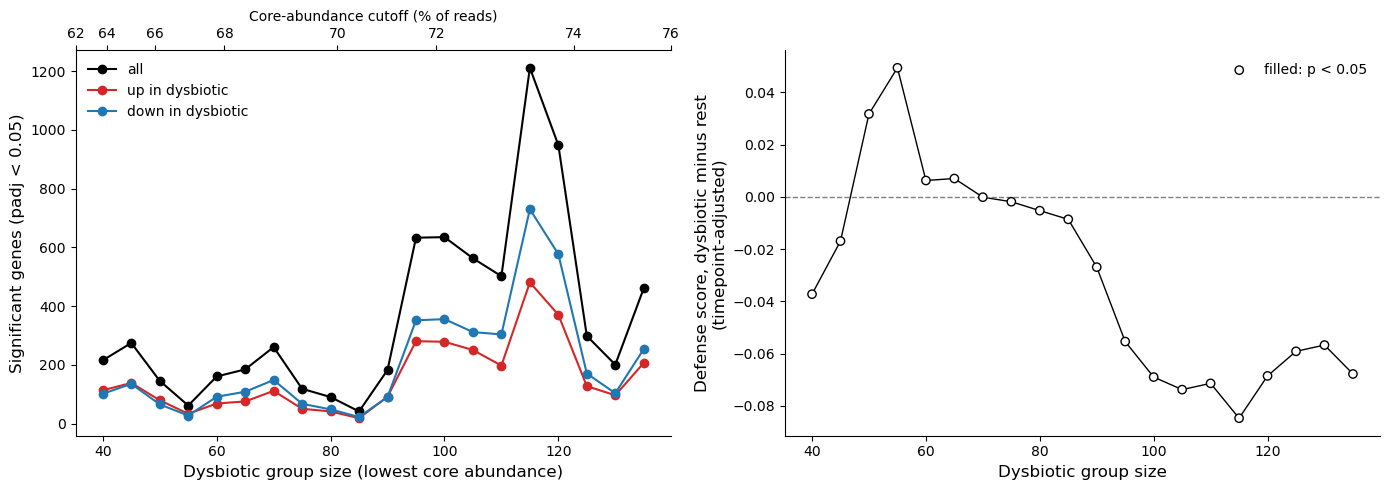

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.patch.set_facecolor("white")
axes[0].plot(core_loss_results.index, core_loss_results["significant (padj < 0.05)"], color="black", marker="o", label="all")
axes[0].plot(core_loss_results.index, core_loss_results["up"], color="tab:red", marker="o", label="up in dysbiotic")
axes[0].plot(core_loss_results.index, core_loss_results["down"], color="tab:blue", marker="o", label="down in dysbiotic")
axes[0].set_xlabel("Dysbiotic group size (lowest core abundance)", fontsize=12)
axes[0].set_ylabel("Significant genes (padj < 0.05)", fontsize=12)
axes[0].legend(frameon=False)
secondary = axes[0].secondary_xaxis(
    "top",
    functions=(
        lambda n: np.interp(n, core_loss_results.index, core_loss_results["cutoff (% of reads in core)"]),
        lambda c: np.interp(c, core_loss_results["cutoff (% of reads in core)"], core_loss_results.index),
    ),
)
secondary.set_xlabel("Core-abundance cutoff (% of reads)")

significant_defense = core_loss_results["defense score diff p"] < 0.05
axes[1].plot(core_loss_results.index, core_loss_results["defense score diff (timepoint-adjusted)"], color="black", linewidth=1)
axes[1].scatter(
    core_loss_results.index,
    core_loss_results["defense score diff (timepoint-adjusted)"],
    c=np.where(significant_defense, "tab:red", "white"),
    edgecolors="black",
    zorder=3,
    label="filled: p < 0.05",
)
axes[1].legend(frameon=False)
axes[1].axhline(0, color="gray", linestyle="dashed", linewidth=1)
axes[1].set_xlabel("Dysbiotic group size", fontsize=12)
axes[1].set_ylabel("Defense score, dysbiotic minus rest\n(timepoint-adjusted)", fontsize=12)
for ax in axes:
    sns.despine(ax=ax)
plt.tight_layout()

## Which samples are in the group?

The group is picked on absolute core abundance (not within timepoint), so it can concentrate in particular parts of the season. Timepoint is in the DESeq2 design, so only timepoints with both dysbiotic and non-dysbiotic samples contribute to the comparison.

In [8]:
sample_info = trimmed_metadata.loc[de_samples, ["timepoint", "Sample Month", "Experiment Type"]].assign(
    core_abund=core_abund
)
month_order = ["November", "December", "January", "February", "March"]
composition = pd.DataFrame(
    {
        n: sample_info.loc[groupings.set_index("group size").loc[n, "high_samples"], "Sample Month"]
        .value_counts()
        .reindex(month_order, fill_value=0)
        for n in group_sizes
    }
).T
composition["% circadian"] = [
    round(100 * (sample_info.loc[groupings.set_index("group size").loc[n, "high_samples"], "Experiment Type"] != "Long Term").mean())
    for n in group_sizes
]
composition["timepoints with a dysbiotic sample"] = [
    sample_info.loc[groupings.set_index("group size").loc[n, "high_samples"], "timepoint"].nunique() for n in group_sizes
]
print("All samples by month:", sample_info["Sample Month"].value_counts().reindex(month_order).to_dict())
composition

All samples by month: {'November': 48, 'December': 40, 'January': 39, 'February': 160, 'March': 139}


Sample Month,November,December,January,February,March,% circadian,timepoints with a dysbiotic sample
40,19,11,4,3,3,10,20
45,21,13,4,3,4,11,21
50,24,13,4,3,6,12,23
55,25,14,5,5,6,11,24
60,25,15,6,7,7,15,27
65,26,15,9,7,8,14,28
70,30,15,9,8,8,13,28
75,30,16,9,10,10,16,28
80,32,16,10,12,10,16,31
85,32,17,11,15,10,18,33


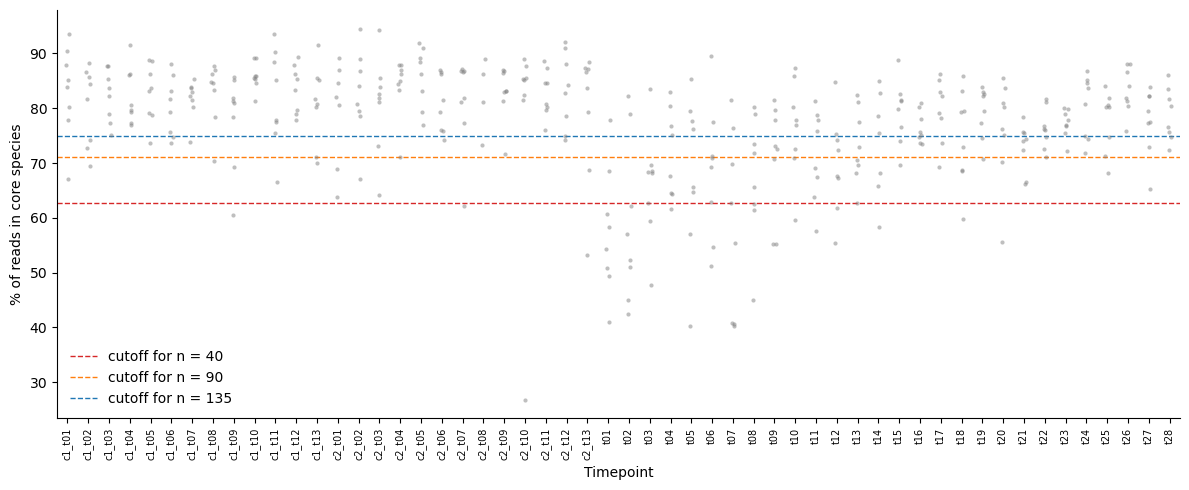

In [9]:
fig, ax = plt.subplots(figsize=(12, 5))
fig.patch.set_facecolor("white")
sns.stripplot(data=sample_info.reset_index(), x="timepoint", y="core_abund", color="gray", alpha=0.5, size=3, ax=ax, order=sorted(sample_info["timepoint"].unique()))
for n, color in [(group_sizes[0], "tab:red"), (group_sizes[len(group_sizes) // 2], "tab:orange"), (group_sizes[-1], "tab:blue")]:
    ax.axhline(groupings.set_index("group size").loc[n, "cutoff (% of reads in core)"], color=color, linestyle="dashed", linewidth=1, label=f"cutoff for n = {n}")
ax.set_xlabel("Timepoint")
ax.set_ylabel("% of reads in core species")
ax.tick_params(axis="x", rotation=90, labelsize=7)
ax.legend(frameon=False)
sns.despine()
plt.tight_layout()

## Stability of the DE genes

Jaccard overlap of the significant gene lists between group sizes, and how many runs each gene is significant in. Genes significant in at least `robust_fraction` of the runs (with a consistent direction) are saved as the robust core-loss gene set.

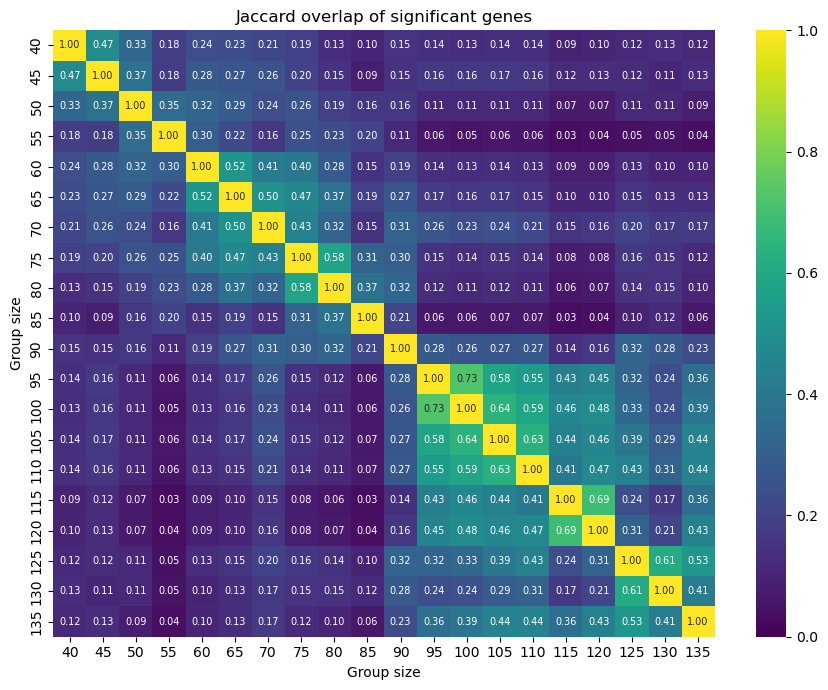

In [10]:
significant_sets = {n: set(r.index[r["padj"] < 0.05]) for n, r in run_results.items()}
jaccard = pd.DataFrame(
    [[len(significant_sets[a] & significant_sets[b]) / max(len(significant_sets[a] | significant_sets[b]), 1) for b in group_sizes] for a in group_sizes],
    index=group_sizes,
    columns=group_sizes,
)
fig, ax = plt.subplots(figsize=(9, 7))
fig.patch.set_facecolor("white")
sns.heatmap(jaccard, annot=True, fmt=".2f", cmap="viridis", vmin=0, vmax=1, annot_kws={"size": 7}, ax=ax)
ax.set_xlabel("Group size")
ax.set_ylabel("Group size")
ax.set_title("Jaccard overlap of significant genes")
plt.tight_layout()

Genes significant in at least one run: 1586
Robust genes (significant in >= 50% of 20 runs, same direction): 173
  up in dysbiotic: 93, down: 80
  defense genes: 3, old DE genes: 19


,runs significant,consistent direction,median log2FC,min padj,defense gene,old DE gene
AT5G28500,20,True,0.2570,0.0001,False,True
AT4G11360,18,True,-0.4202,0.0002,False,False
AT4G28240,16,True,-0.2898,0.0003,False,False
AT1G50010,20,True,0.2382,0.0003,False,False
AT5G17860,17,True,-0.5717,0.0003,False,False
AT1G01120,14,True,0.2155,0.0004,False,False
AT5G45380,11,True,-0.4762,0.0006,False,False
AT1G53520,15,True,0.4211,0.0006,False,False
AT3G04930,13,True,-0.3413,0.0007,False,False
AT4G14870,18,True,0.2611,0.0008,False,False


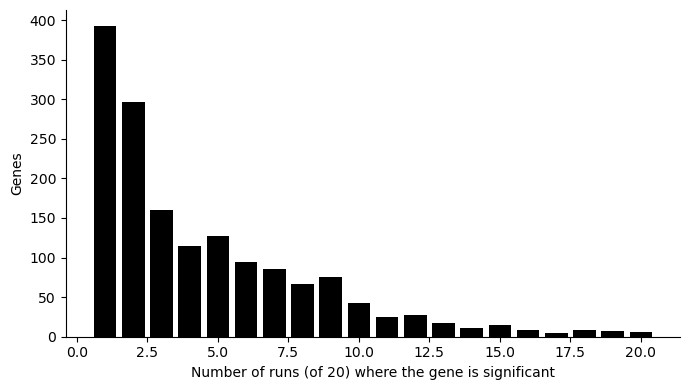

In [11]:
padj = pd.DataFrame({n: r["padj"] for n, r in run_results.items()})
lfc = pd.DataFrame({n: r["log2FoldChange"] for n, r in run_results.items()})
n_significant_runs = (padj < 0.05).sum(axis=1)
direction = np.sign(lfc.where(padj < 0.05)).mean(axis=1)
gene_stability = pd.DataFrame(
    {
        "runs significant": n_significant_runs,
        "consistent direction": direction.abs() == 1,
        "median log2FC": lfc.median(axis=1),
        "min padj": padj.min(axis=1),
        "defense gene": padj.index.isin(defense_genes),
        "old DE gene": padj.index.isin(old_de_genes),
    }
)
robust_genes = gene_stability.loc[
    (gene_stability["runs significant"] >= robust_fraction * len(group_sizes)) & gene_stability["consistent direction"]
].sort_values("min padj")
robust_genes.to_csv(results_dir / "core_loss_robust_genes.csv")
print("Genes significant in at least one run:", (n_significant_runs > 0).sum())
print(f"Robust genes (significant in >= {robust_fraction:.0%} of {len(group_sizes)} runs, same direction): {len(robust_genes)}")
print(f"  up in dysbiotic: {(robust_genes['median log2FC'] > 0).sum()}, down: {(robust_genes['median log2FC'] < 0).sum()}")
print(f"  defense genes: {robust_genes['defense gene'].sum()}, old DE genes: {robust_genes['old DE gene'].sum()}")

fig, ax = plt.subplots(figsize=(7, 4))
fig.patch.set_facecolor("white")
counts = n_significant_runs[n_significant_runs > 0].value_counts().sort_index()
ax.bar(counts.index, counts.values, color="black")
ax.set_xlabel(f"Number of runs (of {len(group_sizes)}) where the gene is significant")
ax.set_ylabel("Genes")
sns.despine()
plt.tight_layout()
robust_genes.head(30).round(4)

## Which core species are lost?

Mean % abundance of each core species in the dysbiotic group vs the rest, at the smallest and largest group size, and how much each one accounts for the gap in total core abundance.

In [12]:
loss_rows = []
for n in [group_sizes[0], group_sizes[-1]]:
    in_group = de_samples.isin(groupings.set_index("group size").loc[n, "high_samples"])
    gap = sample_species.loc[~in_group, core_species].mean() - sample_species.loc[in_group, core_species].mean()
    loss_rows.append(gap.rename(f"loss at n = {n} (% points)"))
core_species_loss = pd.concat(loss_rows, axis=1)
core_species_loss[f"share of total loss at n = {group_sizes[-1]}"] = core_species_loss.iloc[:, -1] / core_species_loss.iloc[:, -1].sum()
core_species_loss.sort_values(core_species_loss.columns[-2], ascending=False).head(15).round(3)

,loss at n = 40 (% points),loss at n = 135 (% points),share of total loss at n = 135
Species,,,
s__Sphingomonas_L_486704 sp000786205,9.043,7.035,0.402
s__Pseudomonas_E_647464 viridiflava,3.474,3.208,0.183
g__Limnohabitans_A Genus,3.229,2.320,0.133
s__Flavobacterium chilense,4.885,2.097,0.120
s__Flavobacterium noncentrifugens,2.827,1.919,0.110
s__Variovorax paradoxus_C,1.493,0.922,0.053
g__Janthinobacterium_571130 Genus,0.924,0.823,0.047
f__Burkholderiaceae_A_595421 Family,2.796,0.783,0.045
s__Sphingomonas_L_486704 sp001423845,1.052,0.618,0.035


In [13]:
# What replaces the core species in the dysbiotic samples (largest group)?
in_group = de_samples.isin(groupings.set_index("group size").loc[group_sizes[-1], "high_samples"])
non_core = sample_species.columns.difference(core_species)
gain = (sample_species.loc[in_group, non_core].mean() - sample_species.loc[~in_group, non_core].mean()).sort_values(ascending=False)
gain_table = pd.DataFrame(
    {
        "gain (% points)": gain,
        "seasonal prevalence": seasonal_prevalence.reindex(gain.index),
    }
)
print(f"Non-core species: {gain[gain > 0].sum():.1f} % points more in dysbiotic samples")
gain_table.head(15).round(3)

Non-core species: 19.3 % points more in dysbiotic samples


,gain (% points),seasonal prevalence
Species,,
s__Sphingomonas_L_486704 metalli,1.351,0.754
s__Duganella zoogloeoides,1.135,0.670
s__Massilia violaceinigra,0.854,0.536
s__Sphingomonas_L_486704 yunnanensis,0.783,0.754
s__Pseudoduganella violaceinigra,0.772,0.754
s__Massilia eurypsychrophila,0.638,0.638
s__Massilia aurea,0.503,0.531
s__Pseudomonas_E_647464 avellanae,0.460,0.594
s__Telluria sp001412595,0.438,0.621


## GO enrichment of the robust genes

Biological-process enrichment (all namespaces in the GO matrix) for the robust up- and downregulated genes, against all genes tested.

In [14]:
go_term_matrix = pd.read_csv("/Users/michael/Data/Reference_data/Arabdidopsis_go_matrix_from_tair_gaf.csv", index_col=0)
go_term_names = pd.read_csv("/Users/michael/Data/Reference_data/goterm_names.csv", index_col=0)
background_genes = de_counts.columns.tolist()
for label, genes in [
    ("up in dysbiotic", robust_genes.index[robust_genes["median log2FC"] > 0]),
    ("down in dysbiotic", robust_genes.index[robust_genes["median log2FC"] < 0]),
]:
    print(f"\n=== Robust genes {label}: {len(genes)} ===")
    if len(genes) < 10:
        print("Too few genes for enrichment")
        continue
    with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
        tables = Go_tools.generate_contigency_tables(
            go_annotations=go_term_matrix, gene_list=genes.tolist(), use_background_genes=True, background_genes=background_genes
        )
        go_results = Go_tools.multi_hypothesis_correct_fishers_exact(
            Go_tools.fishers_exact_on_contigency_tables(all_go_contigency_tables=tables, original_GO_term_panda=go_term_matrix)
        )
    display(go_results.merge(go_term_names, left_index=True, right_index=True, how="left").sort_values("P_value").head(15))


=== Robust genes up in dysbiotic: 93 ===


,P_value,x
GO:0009941,1.285566e-13,chloroplast envelope
GO:0009570,1.075006e-12,chloroplast stroma
GO:0009534,1.436763e-12,chloroplast thylakoid
GO:0009579,4.446645e-09,thylakoid
GO:0009507,4.446645e-09,chloroplast
GO:0009535,4.446645e-09,chloroplast thylakoid membrane
GO:0048046,7.559237e-07,apoplast
GO:0003729,1.618902e-06,mRNA binding
GO:0009536,6.562292e-05,plastid
GO:0009505,1.456788e-04,plant-type cell wall



=== Robust genes down in dysbiotic: 80 ===


,P_value,x
GO:0000323,0.002143,lytic vacuole
GO:0010150,0.461388,leaf senescence
GO:2001141,1.000000,regulation of RNA biosynthetic process
GO:2001080,1.000000,chitosan binding
GO:2001071,1.000000,maltoheptaose binding
GO:2001070,1.000000,starch binding
GO:2001066,1.000000,amylopectin binding
GO:2001057,1.000000,reactive nitrogen species metabolic process
GO:2001011,1.000000,positive regulation of plant-type cell wall ce...
GO:2001009,1.000000,regulation of plant-type cell wall cellulose b...


## Within-timepoint core loss

The absolute ranking above packs the dysbiotic group into early timepoints. Here the dysbiotic plants are instead the `per_timepoint` plants with the lowest % of reads in core species **within each timepoint**, so every timepoint contributes the same number of dysbiotic plants to the `~timepoint + group` comparison. 2 per timepoint is the main run; 1 and 3 per timepoint are run alongside for sensitivity. Timepoints with fewer than `per_timepoint + 2` plants are skipped (none at the moment).

In [15]:
within_timepoint_sizes = [1, 2, 3]
sample_timepoint = trimmed_metadata.loc[de_samples, "timepoint"]
plants_per_timepoint = sample_timepoint.value_counts()
print("Plants per timepoint:", plants_per_timepoint.value_counts().sort_index().to_dict())

within_rows = []
within_results = {}
within_groups = {}
for per_timepoint in within_timepoint_sizes:
    eligible = plants_per_timepoint.index[plants_per_timepoint >= per_timepoint + 2]
    high_samples = pd.Index(
        core_abund[sample_timepoint.isin(eligible)]
        .groupby(sample_timepoint)
        .nsmallest(per_timepoint)
        .index.get_level_values(-1)
    )
    run_id = f"core_loss_prev{core_prevalence_threshold:g}_within_timepoint_lowest{per_timepoint}"
    within_groups[per_timepoint] = high_samples
    within_results[per_timepoint] = run_deseq(run_id, high_samples)
    group_core = core_abund[high_samples]
    within_rows.append(
        {
            "per timepoint": per_timepoint,
            "timepoints used": len(eligible),
            "core % in group (median)": group_core.median(),
            "core % in group (max)": group_core.max(),
            "core % in rest (median)": core_abund.drop(high_samples).median(),
            **summarise_run(within_results[per_timepoint], high_samples),
        }
    )
within_summary = pd.DataFrame(within_rows).set_index("per timepoint")
within_summary.to_csv(results_dir / "core_loss_within_timepoint_summary.csv")
within_summary.round(4)

Plants per timepoint: {4: 1, 7: 2, 8: 51}


,timepoints used,core % in group (median),core % in group (max),core % in rest (median),n High,significant (padj < 0.05),up,down,"significant, |LFC| > 1",min padj,defense genes among significant,old DE genes among significant,defense score diff (timepoint-adjusted),defense score diff p
per timepoint,,,,,,,,,,,,,,
1,54,67.6188,81.2732,80.7694,54,278,173,105,1,0.0000,3,23,-0.0662,0.2826
2,54,71.0289,84.5754,81.7851,108,117,57,60,0,0.0084,1,5,-0.0126,0.7895
3,53,72.6693,85.3581,82.8746,159,10,4,6,0,0.0480,1,1,-0.0108,0.7993


In [16]:
# How the within-timepoint group relates to the absolute groups and their DE genes
main_within = within_groups[2]
main_significant = set(within_results[2].index[within_results[2]["padj"] < 0.05])
comparison_rows = []
for n in group_sizes:
    absolute_group = groupings.set_index("group size").loc[n, "high_samples"]
    comparison_rows.append(
        {
            "absolute group size": n,
            "shared samples": len(set(absolute_group) & set(main_within)),
            "shared DE genes": len(significant_sets[n] & main_significant),
            "absolute DE genes": len(significant_sets[n]),
        }
    )
print(f"Within-timepoint (2 per timepoint): {len(main_within)} plants, {len(main_significant)} DE genes")
print(f"Robust absolute core-loss genes also significant here: {len(set(robust_genes.index) & main_significant)} of {len(robust_genes)}")
print(f"Old species-level DE genes significant here: {len(old_de_genes & main_significant)} of {len(old_de_genes)}")
pd.DataFrame(comparison_rows).set_index("absolute group size").T

Within-timepoint (2 per timepoint): 108 plants, 117 DE genes
Robust absolute core-loss genes also significant here: 49 of 173
Old species-level DE genes significant here: 5 of 59


absolute group size,40,45,50,55,60,65,70,75,80,85,90,95,100,105,110,115,120,125,130,135
shared samples,29,31,34,37,40,42,43,46,49,52,54,58,61,63,65,69,73,76,79,81
shared DE genes,34,40,23,12,30,32,38,20,19,11,37,76,78,79,75,100,99,67,47,83
absolute DE genes,216,275,146,62,161,185,261,119,91,42,183,633,635,563,502,1211,948,299,201,461


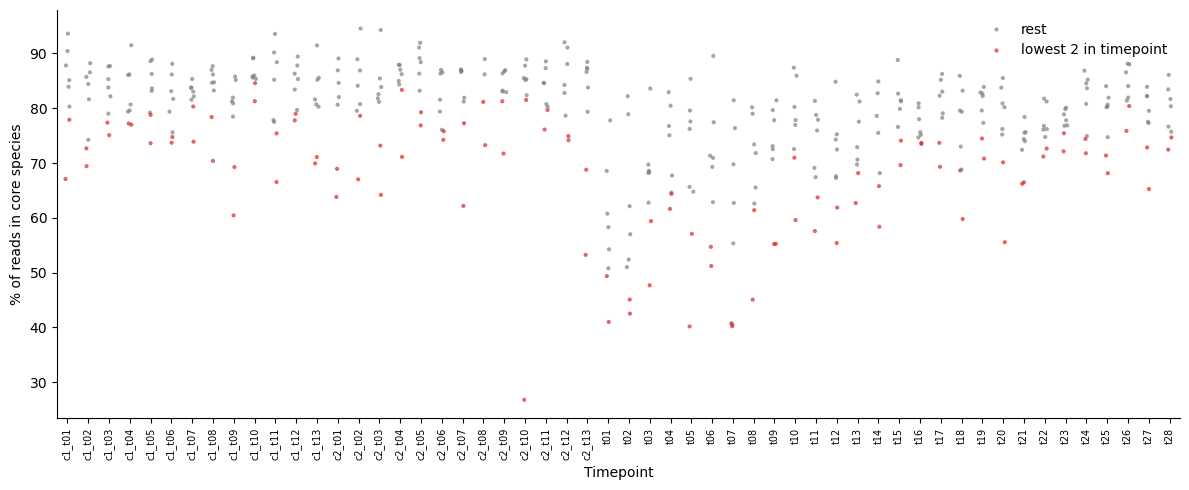

In [17]:
# Core abundance of the within-timepoint group vs the rest, by timepoint
fig, ax = plt.subplots(figsize=(12, 5))
fig.patch.set_facecolor("white")
plot_df = sample_info.assign(group=np.where(de_samples.isin(main_within), "lowest 2 in timepoint", "rest")).reset_index()
sns.stripplot(
    data=plot_df, x="timepoint", y="core_abund", hue="group", palette={"lowest 2 in timepoint": "tab:red", "rest": "gray"},
    size=3, alpha=0.7, order=sorted(sample_info["timepoint"].unique()), ax=ax,
)
ax.set_xlabel("Timepoint")
ax.set_ylabel("% of reads in core species")
ax.tick_params(axis="x", rotation=90, labelsize=7)
ax.legend(frameon=False)
sns.despine()
plt.tight_layout()

In [18]:
significant_within = within_results[2].loc[within_results[2]["padj"] < 0.05].sort_values("padj")
print(f"Up in dysbiotic: {(significant_within['log2FoldChange'] > 0).sum()}, down: {(significant_within['log2FoldChange'] < 0).sum()}")
display(significant_within.head(25)[["baseMean", "log2FoldChange", "padj"]].assign(
    defense_gene=lambda df: df.index.isin(defense_genes), robust_absolute=lambda df: df.index.isin(robust_genes.index)
).round(4))
for label, genes in [
    ("up in dysbiotic", significant_within.index[significant_within["log2FoldChange"] > 0]),
    ("down in dysbiotic", significant_within.index[significant_within["log2FoldChange"] < 0]),
]:
    print(f"\n=== Within-timepoint DE genes {label}: {len(genes)} ===")
    if len(genes) < 10:
        print("Too few genes for enrichment")
        continue
    with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
        tables = Go_tools.generate_contigency_tables(
            go_annotations=go_term_matrix, gene_list=genes.tolist(), use_background_genes=True, background_genes=background_genes
        )
        go_results = Go_tools.multi_hypothesis_correct_fishers_exact(
            Go_tools.fishers_exact_on_contigency_tables(all_go_contigency_tables=tables, original_GO_term_panda=go_term_matrix)
        )
    display(go_results.merge(go_term_names, left_index=True, right_index=True, how="left").sort_values("P_value").head(15))

Up in dysbiotic: 57, down: 60


,baseMean,log2FoldChange,padj,defense_gene,robust_absolute
AT5G38420,11683.3922,0.3253,0.0084,False,True
AT5G28500,1881.8807,0.2090,0.0084,False,True
AT3G05010,111.6736,-0.2307,0.0103,False,False
AT2G23320,178.1541,-0.2949,0.0109,False,False
AT1G20330,254.6232,0.1811,0.0207,False,True
AT3G46000,572.5397,-0.1473,0.0207,False,True
AT3G01150,118.8293,-0.2176,0.0240,False,False
AT1G15400,107.4905,-0.2358,0.0240,False,False
AT3G44590,99.4278,0.3447,0.0240,False,False
AT5G38430,10633.4598,0.2330,0.0240,False,True



=== Within-timepoint DE genes up in dysbiotic: 57 ===


,P_value,x
GO:0009570,1.415278e-09,chloroplast stroma
GO:0009941,2.427895e-07,chloroplast envelope
GO:0009507,8.297643e-06,chloroplast
GO:0009536,9.556671e-05,plastid
GO:0022626,2.233367e-03,cytosolic ribosome
GO:0003729,2.233367e-03,mRNA binding
GO:0009579,3.587563e-03,thylakoid
GO:0009082,7.854081e-02,branched-chain amino acid biosynthetic process
GO:0048046,1.163543e-01,apoplast
GO:0110102,1.313961e-01,ribulose bisphosphate carboxylase complex asse...



=== Within-timepoint DE genes down in dysbiotic: 60 ===


,P_value,x
GO:0000001,1.0,mitochondrion inheritance
GO:0000009,1.0,"alpha-1,6-mannosyltransferase activity"
GO:0000012,1.0,single strand break repair
GO:0000014,1.0,single-stranded DNA endodeoxyribonuclease acti...
GO:0000023,1.0,maltose metabolic process
GO:0000024,1.0,maltose biosynthetic process
GO:0000025,1.0,maltose catabolic process
GO:0000026,1.0,"alpha-1,2-mannosyltransferase activity"
GO:0000027,1.0,ribosomal large subunit assembly
GO:0000028,1.0,ribosomal small subunit assembly
